In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import umap.plot

from sklearn.preprocessing import StandardScaler
import clustering_functions as cf

import warnings
from numba.core.errors import NumbaWarning

warnings.simplefilter('ignore', category=NumbaWarning)

/opt/anaconda3/envs/chem_space_and_clustering/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:23: UserWarning: You are using pyarrow version 11.0.0 which is known to be insecure. See https://www.cve.org/CVERecord?id=CVE-2023-47248 for further details. Please upgrade to pyarrow>=14.0.1 or install pyarrow-hotfix to patch your current version.
  warnings.warn(
/opt/anaconda3/envs/chem_space_and_clustering/lib/python3.9/site-packages/numba/np/ufunc/dufunc.py:343: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/opt/anaconda3/envs/chem_space_and_clustering/lib/python3.9/site-packages/numba/np/ufunc/dufunc.py:343: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compilin

# Read in Data

In [2]:
feature_input_file = 'data/Combined_CyclicOlefin_DFT_Library_for_Molssi' #a file with smiles, descriptors and IDs 
feature_sheet_name = 'Descriptors'
feature_start_column = 3 #column where descriptors start, 0-indexed
feature_header_rows = 0 # adjust as needed 

feature_id_column_name= 'Compound_Name' 
feature_smiles_column_name= None
feature_type_column_name = 'type' #if you don't need to plot any subsets enter: None (not 'None')

#if you want to visualize data by a response variable
response_input_file = None # or leave as None 
response_column_name = None
response_header_rows = 0
response_id_column_name = None #column name for the ID column in the response file, must match the feature ID column name

#_______________________________________________________________________________
#_______________________________________________________________________________
feature_input_df = pd.read_excel(feature_input_file+'.xlsx', sheet_name=feature_sheet_name, header=feature_header_rows)
feature_input_df_shape = feature_input_df.shape
allowed_empty = [feature_smiles_column_name] 
feature_input_df.dropna(subset=[col for col in feature_input_df.columns if col not in allowed_empty], inplace=True) #drop columns with empty values, allow empty smiles
feature_input_df.reset_index(drop=True, inplace=True)
feature_input_df_nona = feature_input_df.shape
if feature_input_df_shape[0] != feature_input_df_nona[0]:
    print('Some rows with missing values were removed')
    print('Original number of datapoints: ', feature_input_df_shape[0])
    print('New number of datapoints: ', feature_input_df_nona[0])

feature_df = feature_input_df.iloc[:,feature_start_column:] #just descriptors 
plotting_data = feature_input_df.copy()

ID = plotting_data[feature_id_column_name]
if feature_smiles_column_name is not None:
   smiles = plotting_data[feature_smiles_column_name]
else:
   plotting_data['smiles'] = 'not available'
   smiles = plotting_data['smiles']

if feature_type_column_name is not None:
   type_column = plotting_data[feature_type_column_name]
   type_column.reset_index(drop=True, inplace=True)
if feature_type_column_name is None:
   type_column = None

if response_input_file is not None:
   response_column = plotting_data[response_column_name]
   response_input = pd.read_excel(response_input_file+'.xlsx', sheet_name=feature_sheet_name, header=response_header_rows)
   response_df = response_input.filter(items=[response_id_column_name, response_column_name])
   plotting_data = pd.merge(response_df, plotting_data, on=response_id_column_name)
else:
   response_column = None

In [3]:
# collinearity filter - add to cell above + have threshold as editing section 
threshold = 0.85
print(f'Shape of descriptors file before removing parameters with R^2 > {threshold} :',feature_df.shape)
df_corr = feature_df.corr()
df_not_correlated = ~(df_corr.mask(np.tril(np.ones([len(df_corr)]*2, dtype=bool))).abs() > threshold).any()
un_corr_idx = df_not_correlated.loc[df_not_correlated[df_not_correlated.index] == True].index
feature_df = feature_df[un_corr_idx]
print(f'Shape of descriptors file after removing parameters with R^2 > {threshold} : ',feature_df.shape)

Shape of descriptors file before removing parameters with R^2 > 0.85 : (869, 688)
Shape of descriptors file after removing parameters with R^2 > 0.85 :  (869, 162)


In [4]:
#scale data
scaler = StandardScaler()
features_scaled = scaler.fit_transform(feature_df)

# Perform Dimensionality Reduction if Needed

### UMAP

#### Run and Plot UMAP

In [ ]:
feature_set = features_scaled
export_to_excel = True #if you want to save as an excel file, set to True
save_plot_as_png = True #if you want to save as a png file, set to True
excel_file_name = 'umap_digits_sample_coordinates.xlsx'
plot_file_name = 'umap_digits_sample_plot.png'
fig_size = (5,5)

#### ------ Set UMAP Hyperparameters --------
# FOR MORE INFO ON UMAP HYPERPARAMETERS: pair-code.github.io/understanding-umap/

n_neighbors = 5 #umap default is 15, reasonable range 3-100
minimum_distance = 0.5 #umap default is 0.1, reasonable range 0.0-0.5
distance_metric = 'euclidean' # or euclidean
random_state = 42 #for reproducibility (on a single machine)

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
color = '#7B1B79' 
edge_color = None
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None

#If you want to plot subsets of data points (i.e. by type)
subgroup = True #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_palette = 'plasma' #color palette or None if you want to use default 
color_dictionary = None # if you want to explicitly define colors for each category instead of using a matplotlib palette {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}

#if you want plot UMAP by a response variable - will override type_column if set to True 
heatmap = False
response_column = None
heatmap_palette = 'plasma' #choose a color palette from matplotlib or None

# if you want to vary marker size, type or alpha by a variable
size_col_name = None # or column name
min_marker_size = 5
max_marker_size = 100

marker_col_name = None # or column name
marker_dict = None # or dictionary {'type_1': 'o', 'type_2': 's', ...} or None if you want to use default cycling through markers

alpha_col_name = None # or column name
min_alpha = 0.3
max_alpha = 1.0
#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

umap_df = cf.dim_reduction_umap(feature_set, 'UMAP1', 'UMAP2',id_column=ID, smiles_column=smiles, excel_filename=excel_file_name,
                             n_neighbors=n_neighbors, min_dist=minimum_distance, n_components=2, distance_metric=distance_metric,
                             random_state=random_state, excel_export=export_to_excel)

umap_fig, umap_ax = cf.plot_chemical_space (df=umap_df, x='UMAP1', y='UMAP2', fig_size=fig_size, xlabel='UMAP1', ylabel='UMAP2',
                                 marker_size = size , marker_color = color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
                                 marker_edge_width=1, title=plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
                                 fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                                 subgroup_palette=subgroup_palette,  category_dict=color_dictionary,  heatmap= heatmap, response_column_name = response_column,
                                 heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size, max_size=max_marker_size,
                                 alpha_col_name =alpha_col_name, min_alpha=min_alpha, max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict, 
                                 input_df = feature_input_df)

### TSNE

#### Run and Plot TSNE

In [ ]:
feature_set = features_scaled
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'tsne_digits_coordinates.xlsx'
plot_file_name = 'tsne_digits_plot.png'
fig_size = (5,5)

#tune hyperparameters 
# for more info on TSNE + TSNE hyperparameters https://distill.pub/2016/misread-tsne/
perplexity = 10 #tsne default is 30
early_exaggeration = 4#tsne default is 12
init = 'pca' #tsne default is 'pca', 'random' may give better results for larger datasets
learning_rate = 'auto' #range 10-1000
max_iterations = 1000 #tsne default is 1000
distance_metric = 'euclidean' 
random_state = 42 #for reproducibility 

#### --- Choose plot parameters --- ###
alpha = 0.4 #transparency of points, 0 is transparent, 1 is opaque
color = '#7B1B79' 
edge_color = None
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None

#If you want to plot subsets of data points (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = None #if subgroup is True, provide column name for subsets else None
subgroup_palette = None #color palette or None if you want to use default 
color_dictionary = None # if you want to explicitly define colors for each category instead of using a matplotlib palette {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}

#if you want plot UMAP by a response variable - will override type_column if set to True 
heatmap = False
response_column = None
heatmap_palette = 'plasma' #choose a color palette from matplotlib or None

# if you want to vary marker size, type or alpha by a variable
size_col_name = None # or column name
min_marker_size = 5
max_marker_size = 100

marker_col_name = None # or column name
marker_dict = None # or dictionary {'type_1': 'o', 'type_2': 's', ...} or None if you want to use default cycling through markers

alpha_col_name = None # or column name
min_alpha = 0.3
max_alpha = 1.0

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

tsne_df = cf.dim_reduction_tsne(feature_set, 'tSNE1', 'tSNE2',
                             id_column=ID, smiles_column=smiles, excel_filename=excel_file_name,
                             n_components=2, perplexity=perplexity, learning_rate=learning_rate,
                             init=init, random_state=random_state, distance_metric=distance_metric,
                            export_excel=export_to_excel)

tsne_fig, tsne_ax  = cf.plot_chemical_space (df=tsne_df, x='tSNE1', y='tSNE2', fig_size=fig_size, xlabel='tSNE1', ylabel='tSNE2',
                                  marker_size=size , marker_color = color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
                                  title = plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
                                  fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                                  subgroup_palette=subgroup_palette,  category_dict=color_dictionary,  heatmap= heatmap, response_column_name = response_column,
                                  heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size, max_size=max_marker_size,
                                  alpha_col_name =alpha_col_name, min_alpha=min_alpha, max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict, 
                                  input_df = feature_input_df)

### PCA

#### Run and Plot PCA

Total variance explained by PCs: 70.4 %

Percentage of explained variance per principal component:
PC1   22.8%
PC2   13.1%
PC3   7.1%
PC4   5.7%
PC5   3.9%
PC6   3.8%
PC7   3.2%
PC8   2.6%
PC9   2.4%
PC10   2.1%
PC11   1.9%
PC12   1.8%
PCA coordinates exported to molssi_10.13.2026.xlsx
PCA feature contributions exported to molssi_10.13.2026_feature_loadings.xlsx
Plot saved as molssi_10.13.2026.png


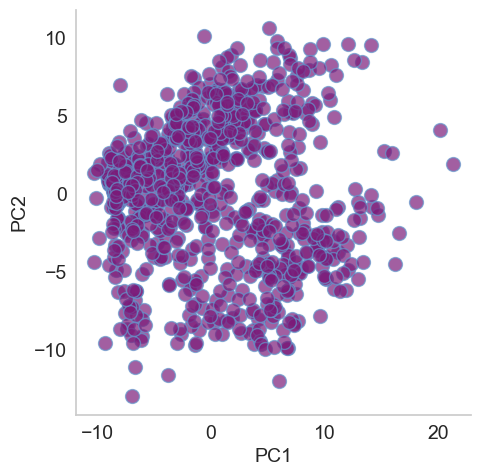

In [8]:
feature_set = features_scaled
export_to_excel = True #if you want to save as an excel file, set to True
save_plot_as_png = True #if you want to save as a png file, set to True
export_feature_loadings_to_excel = True #if you want to save feature loadings as an excel file, set to True
excel_file_name = 'molssi_10.13.2026.xlsx'
feature_loading_file_name = 'molssi_10.13.2026_feature_loadings.xlsx'
plot_file_name = 'molssi_10.13.2026.png'

n_components = 12 #number of components to keep
PCx = 'PC1' #which principal component to plot on x-axis
PCy = 'PC2' #which principal component to plot on y-axis
PCz = None #if you want a 3D plot, specify which principal component to plot on z-axis
 #set to True if you want a 3D plot

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
color = '#7B1B79' 
edge_color = None
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (5,5)

#If you want to plot subsets of data points (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_palette = None #color palette or None if you want to use default 
color_dictionary = {0: "#98d6f4", 1: '#839073'} # if you want to explicitly define colors for each category instead of using a matplotlib palette {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
edge_color = '#6497cc'

#if you want plot UMAP by a response variable - will override type_column if set to True 
heatmap = False
response_column = 'ln(r)'
heatmap_palette = 'plasma' #choose a color palette from matplotlib or None

# if you want to vary marker size, type or alpha by a variable
size_col_name = None # or column name
min_marker_size = 5
max_marker_size = 100

marker_col_name = None # or column name
marker_dict = {0: 'o', 1: '*'} # or dictionary {'type_1': 'o', 'type_2': 's', ...} or None if you want to use default cycling through markers

alpha_col_name = None # or column name
min_alpha = 0.3
max_alpha = 1.0

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
pca_df, pca_feature_contributions = cf.dim_reduction_pca(features=feature_set, n_components=n_components, id_column=ID, smiles_column=smiles,
                            export_pc_coords_excel=export_to_excel, pc_coords_filename=excel_file_name,
                            export_pc_contrib_excel=export_feature_loadings_to_excel, pc_contrib_filename=feature_loading_file_name)

pca_fig, pca_ax  = cf.plot_chemical_space (df=pca_df, x=PCx, y=PCy, z=PCz, fig_size=fig_size, xlabel=PCx, ylabel=PCy, zlabel=PCz,
                                  marker_size=size , marker_color = color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
                                  title = plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
                                  fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                                  subgroup_palette=subgroup_palette, category_dict=color_dictionary, heatmap= heatmap, response_column_name = response_column,
                                  heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size, max_size=max_marker_size,
                                  alpha_col_name =alpha_col_name, min_alpha=min_alpha, max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict, 
                                  input_df = feature_input_df, threedim=True if PCz else False)


In [ ]:
# EDITED PCA CELL
import numpy as np
feature_set = features_scaled
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = True #if you want to save as a png file, set to True
export_feature_loadings_to_excel = True #if you want to save feature loadings as an excel file, set to True
excel_file_name = None
feature_loading_file_name = '870library_highlighting26_with54_expmonomers-edited_manuscriptfinal.xlsx'
plot_file_name = '870library_highlighting26_with54_expmonomers-edited_manuscriptfinal.png'

n_components = 12 #number of components to keep
PCx = 'PC1' #which principal component to plot on x-axis
PCy = 'PC2' #which principal component to plot on y-axis
PCz = None #if you want a 3D plot, specify which principal component to plot on z-axis
 #set to True if you want a 3D plot

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
color = '#7B1B79' 
edge_color = None
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = 'PCA of Monomer Library'
fig_size = (5,5)

#If you want to plot subsets of data points (i.e. by type)
subgroup = True #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_palette = None #color palette or None if you want to use default 
color_dictionary = {0: "#98d6f4", 1: '#839073'} # if you want to explicitly define colors for each category instead of using a matplotlib palette {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
edge_color = '#6497cc'

#if you want plot UMAP by a response variable - will override type_column if set to True 
heatmap = False
response_column = 'ln(r)'
heatmap_palette = 'plasma' #choose a color palette from matplotlib or None

# if you want to vary marker size, type or alpha by a variable
size_col_name = None # or column name
min_marker_size = 5
max_marker_size = 100

marker_col_name = None # or column name
marker_dict = {0: 'o', 1: '*'} # or dictionary {'type_1': 'o', 'type_2': 's', ...} or None if you want to use default cycling through markers

alpha_col_name = None # or column name
min_alpha = 0.3
max_alpha = 1.0

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
pca_df, pca_feature_contributions = cf.dim_reduction_pca(features=feature_set, n_components=n_components, id_column=ID, smiles_column=smiles,
                            export_pc_coords_excel=export_to_excel, pc_coords_filename=excel_file_name,
                            export_pc_contrib_excel=export_feature_loadings_to_excel, pc_contrib_filename=feature_loading_file_name)

import matplotlib.pyplot as plt

# Group labels: use pca_df if it has the column, otherwise the input df
if subgroup_column_name in pca_df.columns:
    groups = pca_df[subgroup_column_name].values
else:
    groups = feature_input_df[subgroup_column_name].values

is_oos = (groups == 1)   # 1 = external test points, 0 = everything else

# 'default' style removes any seaborn despine/grid settings leaking in
with plt.style.context('default'):
    fig, ax = plt.subplots(figsize=(3, 3))

    # ALL points (same colors/sizes as the KRR plot)
    ax.scatter(pca_df.loc[~is_oos, PCx], pca_df.loc[~is_oos, PCy],
                color="#98d6f4", edgecolor="#6498cc", s=25, alpha=0.9, label="Library")

    # OOS points drawn on top
    ax.scatter(pca_df.loc[is_oos, PCx], pca_df.loc[is_oos, PCy],
                color="#d9d7d7", edgecolor="#414042", s=25, alpha=0.9, label="Experimental")

    ax.set_xlabel(PCx, fontsize = 8)
    ax.set_ylabel(PCy, fontsize = 8)
    ax.set_title(plot_title, fontsize = 10)
    ax.tick_params(axis='both', labelsize=8)
    ax.legend(fontsize=6, loc="best", frameon=True)   # no box around legend

    # Same limits on both axes, symmetric around 0, rounded up to the next 2
    # lim = np.ceil(max(pca_df[PCx].abs().max(), pca_df[PCy].abs().max()) / 2) * 2
    # ax.set_xlim(-lim, lim)
    # ax.set_ylim(-lim, lim)
    # ax.set_aspect('equal', adjustable='box')           # 1 unit on x = 1 unit on y

    ax.set_box_aspect(1)          # square frame like the KRR plot
    fig.tight_layout()

    if save_plot_as_png:
        fig.savefig(plot_file_name, dpi=300, bbox_inches="tight")
        fig.savefig("870library_highlightingexpmonomers-edited_manuscriptfinal_oct10.svg", dpi=300, bbox_inches="tight")  # if you want SVG like the KRR one
    plt.show()


In [ ]:
# Attach real feature names to the PCA loadings
loadings = pd.DataFrame(pca_feature_contributions).copy()

# make sure rows = features, columns = PCs
if loadings.shape[0] != feature_df.shape[1] and loadings.shape[1] == feature_df.shape[1]:
    loadings = loadings.T

assert loadings.shape[0] == feature_df.shape[1], "Loadings rows don't match number of features"
loadings.index = feature_df.columns      # same order as features_scaled
loadings.index.name = 'feature'

# Top contributing features for each PC (signed loading, sorted by magnitude)
top_n = 12
for pc in loadings.columns:
    top = loadings[pc].loc[loadings[pc].abs().sort_values(ascending=False).index].head(top_n)
    print(f'\n=== {pc} ===')
    print(top.round(3).to_string())

# Optional: save the full labeled table
loadings.to_excel('pca_feature_loadings_labeled_sept20.xlsx')

### Plot Descriptor vs. Descriptor

#### Simple Decriptor v. Descriptor (v. Descriptor) Plotting

In [ ]:
feature_set = pd.DataFrame(feature_df, columns=feature_df.columns)
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'feature1_vs_feature2_coordinates.xlsx'
plot_file_name = 'feature1_vs_feature2_plot.png'

feature_y= 'NBO_charge_CC2_range'
feature_x = 'Hirsh_atom_dipole_C1_range'  ##KEEP bc 0.186
feature_z = None

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
color = '#7B1B79' 
edge_color = None
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (4,4) # figure size in inches

#If you want to plot subsets of data points (i.e. by type)
subgroup = True #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_palette = None #color palette or None if you want to use default 
color_dictionary = {0: 'blue', 1: "red"} # if you want to explicitly define colors for each category instead of using a matplotlib palette {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}

#if you want plot UMAP by a response variable - will override type_column if set to True 
heatmap = False
response_column = None
heatmap_palette = 'plasma' #choose a color palette from matplotlib or None

# if you want to vary marker size, type or alpha by a variable
size_col_name = None # or column name
min_marker_size = 5
max_marker_size = 100

marker_col_name = None # or column name
marker_dict = None # or dictionary {'type_1': 'o', 'type_2': 's', ...} or None if you want to use default cycling through markers

alpha_col_name = None # or column name
min_alpha = 0.3
max_alpha = 1.0

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
chem_space_df = cf.feat_v_feat (features=feature_set, id_column=ID, smiles_column=smiles, feature_x=feature_x, feature_y=feature_y, feature_z=feature_z)

chem_space_fig, chem_space_ax = cf.plot_chemical_space (df=chem_space_df, x=feature_x, y=feature_y, z=feature_z, fig_size=fig_size, xlabel=feature_x, ylabel=feature_y, zlabel=feature_z,
                                  marker_size=size , marker_color = color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
                                  title = plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
                                  fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                                  subgroup_palette=subgroup_palette, category_dict=color_dictionary,  heatmap= heatmap, response_column_name = response_column,
                                  heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size, max_size=max_marker_size,
                                  alpha_col_name =alpha_col_name, min_alpha=min_alpha, max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict, 
                                  input_df = feature_input_df, threedim=False)

In [ ]:
feature_set = pd.DataFrame(feature_df, columns=feature_df.columns)
export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'feature1_vs_feature2_coordinates.xlsx'
plot_file_name = 'feature1_vs_feature2_plot.png'

feature_x= 'M1_NBO_charge_CC2_low_E-M2_NBO_charge_CC2_low_E' 
feature_y = 'M1_η_Boltz'  
feature_z = None  # if you want to plot in 3D, set to 'feature#'

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
color = '#7B1B79' 
edge_color = None
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None

#If you want to plot subsets of data points (i.e. by type)
subgroup = True #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_palette = None #color palette or None if you want to use default 
color_dictionary = {0: 'gray', 1: "red"} # if you want to explicitly define colors for each category instead of using a matplotlib palette {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}

#if you want plot UMAP by a response variable - will override type_column if set to True 
heatmap = False
response_column = None
heatmap_palette = 'plasma' #choose a color palette from matplotlib or None

# if you want to vary marker size, type or alpha by a variable
size_col_name = None # or column name
min_marker_size = 5
max_marker_size = 100

marker_col_name = None # or column name
marker_dict = None # or dictionary {'type_1': 'o', 'type_2': 's', ...} or None if you want to use default cycling through markers

alpha_col_name = None # or column name
min_alpha = 0.3
max_alpha = 1.0

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
chem_space_df = cf.feat_v_feat (features=feature_set, id_column=ID, smiles_column=smiles, feature_x=feature_x, feature_y=feature_y, feature_z=feature_z)

chem_space_fig, chem_space_ax = cf.plot_chemical_space (df=chem_space_df, x=feature_x, y=feature_y, fig_size=fig_size, xlabel=feature_x, ylabel=feature_y,
                                  marker_size=size , marker_color = color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
                                  title = plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
                                  fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                                  subgroup_palette=subgroup_palette, category_dict=color_dictionary,  heatmap= heatmap, response_column_name = response_column,
                                  heatmap_palette=heatmap_palette, size_col_name=size_col_name, min_size=min_marker_size, max_size=max_marker_size,
                                  alpha_col_name =alpha_col_name, min_alpha=min_alpha, max_alpha=max_alpha, marker_col=marker_col_name, marker_dict=marker_dict, 
                                  input_df = feature_input_df)


### Plot Interactive Chemical Space

In [ ]:
df = pca_df
x_coordinates = 'PC1'
y_coordinates = 'PC2'
id_column = 'id'
smiles_column = None

#stylize markers
alpha = 0.7 #transparency of points
color = '#7B1B79' 
marker = 'circle' #point shape
size = 10 #point size
linewidth = 1
linecolor = 'black'

#if you want to stylize markers by a reponse variable
size_column = None #column name for size scaling
alpha_column = None #column name for alpha scaling
marker_column = None #column name for marker shapes

#stylize figure 
title = 'Chemical Space Map by PCA'
x_label = 'Principal Component 1'
y_label = 'Principal Component 2'
fig_width = 600
fig_height = 600

###### -------- if you want to plot subgroups -------- ######
subgroup = False #change to True if you want to plot subgroups
subgroup_col = 'type' #column name for subgroups
subgroup_palette = None #change to continous color pallette if desired
categorical = False #or set to True if you want discrete colors for subgroups
category_dict = None #enter dict of custom colors: {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
categorical_palette = None #or choose a plotly categorical palette if desired

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

int_plot = cf.int_scatter_dash(df, x_col = x_coordinates, y_col = y_coordinates, 
            smiles_col=smiles_column, id_col=id_column, molSize=(150,150), 
            marker_size=size, marker_symbol=marker, marker_color=color,
            marker_alpha = 0.7, linewidth=linewidth, lincolor=linecolor, 
            plot_title=title, x_label=x_label, y_label=y_label, fig_width=fig_width, fig_height=fig_height,
            subgroup=subgroup, subgroup_col=subgroup_col, subgroup_palette=subgroup_palette,
            categorical=categorical, category_dict=category_dict, categorical_palette=categorical_palette,
            size_col=None, min_size=1, max_size=20,
            alpha_col=None, min_alpha=0.5, max_alpha=1.0,
            marker_col=None,debug=False)

# Clustering Techniques

### Choose Number of Clusters (Optional)

In [ ]:
# see silhouette scores for different numbers of clusters
# ideal plot: clusters have above average silhouette scores, size of the silhouette plots are similar 
# and thickness of the plot for each cluster is uniform
# higher score (up to 1) indicates better clustering

scoring_method = 'silhouette_scores' #options: silhouette_scores, aic_bic_scores, elbow_method

df = umap_df
X_coordinate_column = 'UMAP1'
Y_coordinate_column = 'UMAP2'

random_state = 42
min_clusters = 2
max_clusters = 10
clustering_algorithm = cf.kmeans_clustering

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
if scoring_method == 'silhouette_scores':
    silhouette_scoring = cf.silhouette_scores(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm, random_state)
elif scoring_method == 'aic_bic_scores':
    aic_scoring = cf.aic_bic_inertia_scores(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm, random_state)  
elif scoring_method == 'elbow_method':
    elbow_method = cf.elbow_method(df, X_coordinate_column, Y_coordinate_column, min_clusters, max_clusters, clustering_algorithm)
else:
    print('Invalid scoring method')


### Choose Clustering Algorithm 

In [ ]:
df = umap_df
X_coordinate_column = 'UMAP1'
Y_coordinate_column = 'UMAP2'
random_state = 42

#### HDBSCAN

In [ ]:
#for more info on hyperparameters: hdbscan.readthedocs.io/en/latest/parameter_selection.html
min_cluster_size = 25
min_samples = 15
distance_metric = 'manhattan'

export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'hdbscan_clusters_and_coordinates.xlsx'
plot_file_name = 'hdbscan_clusters_plot.png'

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
edge_color = None
cluster_color_map = 'plasma'
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (5,5)

#If you want to plot subsets of data points in ADDITION to HDBSCAN clusters (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_marker = 'D' #marker shape for subgroup points
subgroup_plot_dict = {'tested': 'plot', 'untested': 'skip'}
subgroup_palette = None #color palette or None if you want to use default 

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
hdbscan_clusters, hdbscan_clusters_df = cf.hdbscan_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state,min_cluster_size, min_samples, distance_metric)

hdbscan_plot = cf.cluster_plots(df = hdbscan_clusters_df, x=X_coordinate_column, cluster_column='cluster', cluster_color_map=cluster_color_map,
                            y=Y_coordinate_column,xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
                            marker_size = size , marker_color = color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
                            title = plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
                            fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                            subgroup_palette=subgroup_palette, size_col_name=size_col_name, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
                            subgroup_marker=subgroup_marker)

#### DBSCAN

In [ ]:
# for more info on hyperparameters: scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
eps = 0.5
min_samples = 5
distance_metric = 'manhattan'

export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'dbscan_clusters_and_coordinates.xlsx'
plot_file_name = 'dbscan_clusters_plot.png'

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
edge_color = None
cluster_color_map = 'plasma'
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (5,5)

#If you want to plot subsets of data points in ADDITION to HDBSCAN clusters (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_marker = 'D' #marker shape for subgroup points
subgroup_plot_dict = {'tested': 'plot', 'untested': 'skip'}
subgroup_palette = None #color palette or None if you want to use default 

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
dbscan_clusters, dbscan_clusters_df = cf.dbscan_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state,distance_metric, eps, min_samples)

dbscan_plot = cf.cluster_plots(df = dbscan_clusters_df, x=X_coordinate_column, cluster_column='cluster', cluster_color_map=cluster_color_map,
                            y=Y_coordinate_column,xlabel=X_coordinate_column, ylabel=Y_coordinate_column,
                            marker_size = size , marker_color = color, alpha=alpha, marker=marker, marker_edge_color=edge_color,
                            title = plot_title, save_plot=save_plot_as_png, plot_filename=plot_file_name,
                            fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                            subgroup_palette=subgroup_palette, size_col_name=size_col_name, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
                            subgroup_marker=subgroup_marker)

#### K-Means Clustering

In [ ]:
#number of clusters should be selected using one of the algorithms above!
# please do not use this with UMAP 
n_clusters = 5

export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'dbscan_clusters_and_coordinates.xlsx'
plot_file_name = 'dbscan_clusters_plot.png'

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
edge_color = None
cluster_color_map = 'plasma'
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (5,5)

#If you want to plot subsets of data points in ADDITION to HDBSCAN clusters (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_marker = 'D' #marker shape for subgroup points
subgroup_plot_dict = {'tested': 'plot', 'untested': 'skip'}
subgroup_palette = None #color palette or None if you want to use default 

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
kmeans_clusters, kmeans_clusters_df = cf.kmeans_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters)

kmeans_plot = cf.cluster_plots(df = kmeans_clusters_df, x=X_coordinate_column, y= Y_coordinate_column, cluster_column='cluster', cluster_color_map=cluster_color_map,
                            xlabel=X_coordinate_column, ylabel=Y_coordinate_column,marker_size = size , marker_color = color, alpha=alpha,
                            marker=marker, marker_edge_color=edge_color,title = plot_title, save_plot=save_plot_as_png,plot_filename=plot_file_name,
                            fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                            subgroup_palette=subgroup_palette, size_col_name=size_col_name, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
                            subgroup_marker=subgroup_marker)

#### GMM Clustering

In [ ]:
#for more info on covariance types: scikit-learn.org/stable/auto_examples/mixture/plot_gmm_covariances.html#sphx-glr-auto-examples-mixture-plot-gmm-covariances-py
n_clusters = 5
covariance_type = 'full'

export_to_excel = False #if you want to save as an excel file, set to True
save_plot_as_png = False #if you want to save as a png file, set to True
excel_file_name = 'dbscan_clusters_and_coordinates.xlsx'
plot_file_name = 'dbscan_clusters_plot.png'

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
edge_color = None
cluster_color_map = 'plasma'
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (5,5)

#If you want to plot subsets of data points in ADDITION to HDBSCAN clusters (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_marker = 'D' #marker shape for subgroup points
subgroup_plot_dict = {'tested': 'plot', 'untested': 'skip'}
subgroup_palette = None #color palette or None if you want to use default 

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
gmm_clusters, gmm_clusters_df = cf.gmm_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters, covariance_type)

gmm_plot = cf.cluster_plots(df = gmm_clusters_df, x=X_coordinate_column, y= Y_coordinate_column, cluster_column='cluster', cluster_color_map=cluster_color_map,
                            xlabel=X_coordinate_column, ylabel=Y_coordinate_column,marker_size = size , marker_color = color, alpha=alpha,
                            marker=marker, marker_edge_color=edge_color,title = plot_title, save_plot=save_plot_as_png,plot_filename=plot_file_name,
                            fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                            subgroup_palette=subgroup_palette, size_col_name=size_col_name, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
                            subgroup_marker=subgroup_marker)


#### Agglomerative Clustering (Ward Clustering)

In [ ]:
# for more info on hyperparameters: scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html
n_clusters = 5
distance_metric = 'euclidean'
linkage_type = 'ward'

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
edge_color = None
cluster_color_map = 'plasma'
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (5,5)

#If you want to plot subsets of data points in ADDITION to HDBSCAN clusters (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_marker = 'D' #marker shape for subgroup points
subgroup_plot_dict = {'tested': 'plot', 'untested': 'skip'}
subgroup_palette = None #color palette or None if you want to use default 
#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
agglomerative_clusters, agg_clusters_df = cf.agglomerative_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters, distance_metric, linkage_type)

agglomerative_plot = cf.cluster_plots(df = agg_clusters_df, x=X_coordinate_column, y= Y_coordinate_column, cluster_column='cluster', cluster_color_map=cluster_color_map,
                            xlabel=X_coordinate_column, ylabel=Y_coordinate_column,marker_size = size , marker_color = color, alpha=alpha,
                            marker=marker, marker_edge_color=edge_color,title = plot_title, save_plot=save_plot_as_png,plot_filename=plot_file_name,
                            fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                            subgroup_palette=subgroup_palette, size_col_name=size_col_name, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
                            subgroup_marker=subgroup_marker)


#### BIRCH Clustering

In [ ]:
# for more info on hyperparameters: scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html
n_clusters = 5
threshold = 0.5 
branching_factor = 50

#### --- Choose plot parameters --- ###
alpha = 0.7 #transparency of points, 0 is transparent, 1 is opaque
edge_color = None
cluster_color_map = 'plasma'
marker = 'o' #point shape
size = 100 #point size
ax_font_size = 14
title_font_size = 16
plot_title = None
fig_size = (5,5)

#If you want to plot subsets of data points in ADDITION to HDBSCAN clusters (i.e. by type)
subgroup = False #set to True if you want to plot subsets
subgroup_column_name = 'type' #if subgroup is True, provide column name for subsets else None
subgroup_marker = 'D' #marker shape for subgroup points
subgroup_plot_dict = {'tested': 'plot', 'untested': 'skip'}
subgroup_palette = None #color palette or None if you want to use default 
#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________
birch_clusters, birch_clusters_df = cf.BIRCH_clustering(df, X_coordinate_column, Y_coordinate_column, 
                                      random_state, n_clusters, threshold, branching_factor)

birch_plot = cf.cluster_plots(df = birch_clusters_df, x=X_coordinate_column, y= Y_coordinate_column, cluster_column='cluster', cluster_color_map=cluster_color_map,
                            xlabel=X_coordinate_column, ylabel=Y_coordinate_column,marker_size = size , marker_color = color, alpha=alpha,
                            marker=marker, marker_edge_color=edge_color,title = plot_title, save_plot=save_plot_as_png,plot_filename=plot_file_name,
                            fontsize=ax_font_size, title_fontsize=title_font_size, subgroup=subgroup, subgroup_column_name=subgroup_column_name,
                            subgroup_palette=subgroup_palette, size_col_name=size_col_name, fig_size=fig_size, subgroup_plot_dict=subgroup_plot_dict,
                            subgroup_marker=subgroup_marker)

### Interactive Plot with Clusters

In [ ]:
df = gmm_clusters_df
x_coordinates = 'UMAP1'
y_coordinates = 'UMAP2'
id_column = 'id'
smiles_column = 'smiles'

#stylize markers
alpha = 0.7 #transparency of points
color = '#7B1B79' 
marker = 'circle' #point shape
size = 10 #point size
linewidth = 1
linecolor = 'black'

#if you want to stylize markers by a reponse variable
size_column = None #column name for size scaling
alpha_column = None #column name for alpha scaling
marker_column = None #column name for marker shapes

#stylize figure 
title = 'Chemical Space Map by PCA'
x_label = 'UMAP1'
y_label = 'UMAP2'
fig_width = 600
fig_height = 600

###### -------- if you want to plot subgroups -------- ######
subgroup = True #change to True if you want to plot subgroups
subgroup_col = 'cluster' #column name for subgroups
subgroup_palette = None #change to continous color pallette if desired
categorical = False #or set to True if you want discrete colors for subgroups
category_dict = None #enter dict of custom colors: {'type_1': '#7B1B79', 'type_2': '#FFA07A', ...}
categorical_palette = None #or choose a plotly categorical palette if desired

#_______________________________________________________________________________
                        #shouldn't need to adjust below here
#_______________________________________________________________________________

int_plot = cf.int_scatter_dash(df, x_col = x_coordinates, y_col = y_coordinates, 
            smiles_col=smiles_column, id_col=id_column, molSize=(150,150), 
            marker_size=size, marker_symbol=marker, marker_color=color,
            marker_alpha = 0.7, linewidth=linewidth, lincolor=linecolor, 
            plot_title=title, x_label=x_label, y_label=y_label, fig_width=fig_width, fig_height=fig_height,
            subgroup=subgroup, subgroup_col=subgroup_col, subgroup_palette=subgroup_palette,
            categorical=categorical, category_dict=category_dict, categorical_palette=categorical_palette,
            size_col=None, min_size=1, max_size=20,
            alpha_col=None, min_alpha=0.5, max_alpha=1.0,
            marker_col=None,debug=False)